In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# plt.rcParams['font.family'] = 'serif'
# plt.rcParams['font.serif'] = ['Times New Roman']
# plt.rcParams['mathtext.fontset'] = 'stix' # Matches math symbols to Times New Roman

def plot_gr_csv(paths):
    """
    For each CSV in `paths`, create one plot:
      - g(r) on left axis
      - Integral on right axis
      - Save figure as <path>.jpg
    """

    # Ensure paths is a list
    if isinstance(paths, str):
        paths = [paths]

    for path in paths:
        # Read CSV
        df = pd.read_csv(
            path,
            sep=';',
            comment='#',
            header=None,
            names=['Distance_pm', 'g_r', 'Integral']
        )

        # --- Plot ---
        fig, ax1 = plt.subplots()
        ax2 = ax1.twinx()

        # Left axis: g(r)
        ax1.plot(df['Distance_pm'], df['g_r'], color='tab:blue', label='g(r)')
        ax1.set_xlabel("Distance (pm)")
        ax1.set_ylabel("n(r)", color='tab:blue')
        ax1.tick_params(axis='y', labelcolor='tab:blue')
        ax1.grid(True)

        # Right axis: Integral
        ax2.plot(df['Distance_pm'], df['Integral'], color='tab:red', linestyle='--', label='Integral')
        ax2.set_ylabel("Coordination", color='tab:red')
        ax2.tick_params(axis='y', labelcolor='tab:red')

        plt.title(f"g(r) and Integral vs Distance\n{os.path.basename(path)}")
        plt.tight_layout()

        # Save as JPG
        save_path = str(path) + ".png"
        plt.savefig(save_path)
        plt.show()

        print(f"Saved: {save_path}")


In [2]:
from pathlib import Path

def list_csv_files(directory):
    directory = Path(directory)
    return sorted(directory.glob("*.csv"), key=lambda p: p.name)

# Example
csv_paths = list_csv_files(".")
print(csv_paths)



[PosixPath('pure_2_pentanol.csv'), PosixPath('rdf_C5H12O_C4Cl2H8_[O1r_Ho].csv'), PosixPath('rdf_C5H12O_C5H12O_[O1r_Ho].csv')]


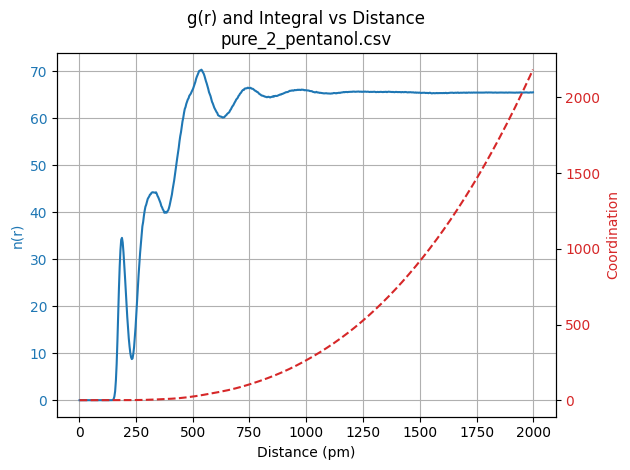

Saved: pure_2_pentanol.csv.png


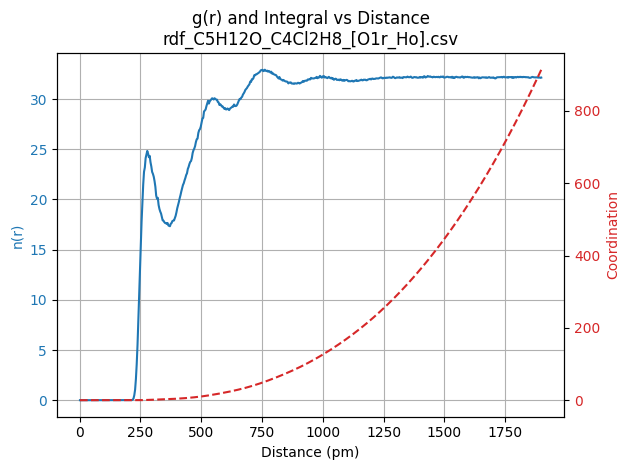

Saved: rdf_C5H12O_C4Cl2H8_[O1r_Ho].csv.png


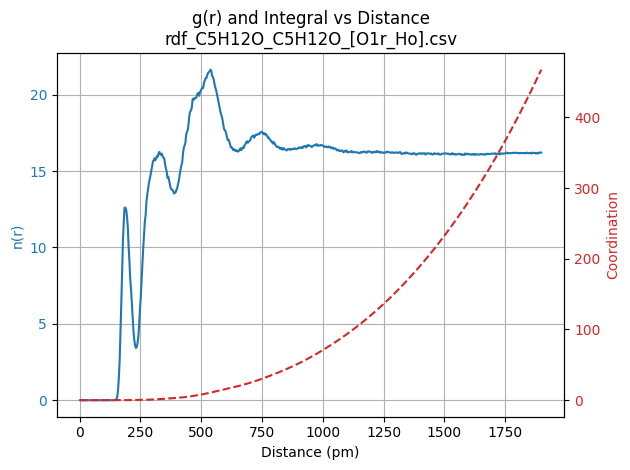

Saved: rdf_C5H12O_C5H12O_[O1r_Ho].csv.png


In [3]:
plot_gr_csv(csv_paths)

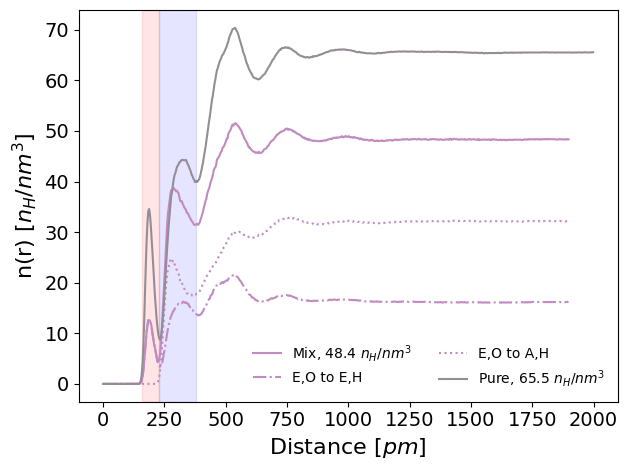

In [9]:
import numpy as np

df_alcohol = pd.read_csv(
    "rdf_C5H12O_C5H12O_[O1r_Ho].csv",
    sep=';',
    comment='#',
    header=None,
    names=['Distance_pm', 'g_r', 'Integral']
)

df_Cl = pd.read_csv(
    "rdf_C5H12O_C4Cl2H8_[O1r_Ho].csv",
    sep=';',
    comment='#',
    header=None,
    names=['Distance_pm', 'g_r', 'Integral']
)

df_pure_alcohol = pd.read_csv(
    "pure_2_pentanol.csv",
    sep=';',
    comment='#',
    header=None,
    names=['Distance_pm', 'g_r', 'Integral']
)

# plt.plot(df['Distance_pm'], df['g_r'], label=path.stem)
plt.plot(df_alcohol['Distance_pm'], (df_alcohol['g_r']+df_Cl['g_r']), color="#c18ac1", label=rf"Mix, {np.round((3092/3.9985042**3), 1)} $n_H/nm^3$")
plt.plot(df_alcohol['Distance_pm'], df_alcohol['g_r'], label="E,O to E,H", color="#c18ac1", linestyle='-.')
plt.plot(df_alcohol['Distance_pm'], df_Cl['g_r'], label="E,O to A,H", color="#c18ac1", linestyle='dotted')
plt.plot(df_pure_alcohol['Distance_pm'], df_pure_alcohol['g_r'], color= "#948d96", label=rf"Pure, {np.round(((351*12)/4.0060769**3), 1)} $n_H/nm^3$")
# plt.axhline(y=(3092/3.9985042**3), linestyle='--', color="#c18ac1", label=rf"Mix, {np.round((3092/3.9985042**3), 1)} $n_H/nm^3$") # label="Mix, A:0.75, E:0.25"
# plt.axhline(y=((351*12)/4.0060769**3), linestyle='--', color= "#948d96", label=rf"Pure, {np.round(((351*12)/4.0060769**3), 1)} $n_H/nm^3$") # label="Pure, E:1.00"
# plt.axhline(y=(3092/3.9985042**3), linestyle='--', color="#c18ac1") # label="Mix, A:0.75, E:0.25"
# plt.axhline(y=((351*12)/4.0060769**3), linestyle='--', color= "#948d96", label=rf"Pure, {np.round(((351*12)/4.0060769**3), 1)} $n_H/nm^3$") # label="Pure, E:1.00"

# Original
# plt.plot(df_alcohol['Distance_pm'], (df_alcohol['g_r']+df_Cl['g_r'])/(3092/4.04044**3), label="Mix, A:0.75, E:0.25", color="#c18ac1")
# plt.plot(df_pure_alcohol['Distance_pm'], df_pure_alcohol['g_r']/((351*12)/4.02248**3), label="Pure, E:1.00", color= "#948d96")

# --- vertical shaded red region ---
plt.axvspan(
    160, 230,
    color="red",
    alpha=0.10,
    zorder=0
)
plt.axvspan(
    230, 380,
    color="blue",
    alpha=0.10,
    zorder=0
)
# plt.axvspan(
#     380, 630,
#     color="gray",
#     alpha=0.10,
#     zorder=0
# )

plt.xlabel(rf"Distance $[pm]$", fontsize=16)
# plt.ylabel("g(r)", fontsize=16)
plt.ylabel(rf"n(r) $[n_H/nm^3]$", fontsize=16)
# plt.title("All CSV g(r) Curves")
plt.legend(loc="lower right", ncol=2, fontsize=10, frameon=False)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig("visc_mix_decomposed.svg", dpi=300)
plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


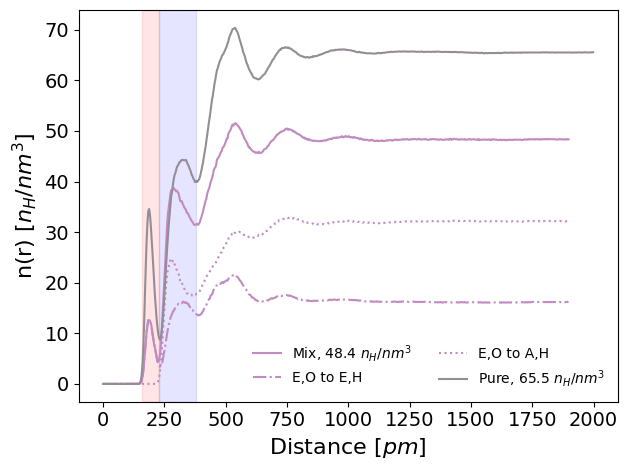

In [5]:
import numpy as np

df_alcohol = pd.read_csv(
    "rdf_C5H12O_C5H12O_[O1r_Ho].csv",
    sep=';',
    comment='#',
    header=None,
    names=['Distance_pm', 'g_r', 'Integral']
)

df_Cl = pd.read_csv(
    "rdf_C5H12O_C4Cl2H8_[O1r_Ho].csv",
    sep=';',
    comment='#',
    header=None,
    names=['Distance_pm', 'g_r', 'Integral']
)

df_pure_alcohol = pd.read_csv(
    "pure_2_pentanol.csv",
    sep=';',
    comment='#',
    header=None,
    names=['Distance_pm', 'g_r', 'Integral']
)

# plt.plot(df['Distance_pm'], df['g_r'], label=path.stem)
plt.plot(df_alcohol['Distance_pm'], (df_alcohol['g_r']+df_Cl['g_r']), color="#c18ac1", label=rf"Mix, {np.round((3092/3.9985042**3), 1)} $n_H/nm^3$")
plt.plot(df_alcohol['Distance_pm'], df_alcohol['g_r'], label="E,O to E,H", color="#c18ac1", linestyle='-.')
plt.plot(df_alcohol['Distance_pm'], df_Cl['g_r'], label="E,O to A,H", color="#c18ac1", linestyle='dotted')
plt.plot(df_pure_alcohol['Distance_pm'], df_pure_alcohol['g_r'], color= "#948d96", label=rf"Pure, {np.round(((351*12)/4.0060769**3), 1)} $n_H/nm^3$")
# plt.axhline(y=(3092/3.9985042**3), linestyle='--', color="#c18ac1", label=rf"Mix, {np.round((3092/3.9985042**3), 1)} $n_H/nm^3$") # label="Mix, A:0.75, E:0.25"
# plt.axhline(y=((351*12)/4.0060769**3), linestyle='--', color= "#948d96", label=rf"Pure, {np.round(((351*12)/4.0060769**3), 1)} $n_H/nm^3$") # label="Pure, E:1.00"
# plt.axhline(y=(3092/3.9985042**3), linestyle='--', color="#c18ac1") # label="Mix, A:0.75, E:0.25"
# plt.axhline(y=((351*12)/4.0060769**3), linestyle='--', color= "#948d96", label=rf"Pure, {np.round(((351*12)/4.0060769**3), 1)} $n_H/nm^3$") # label="Pure, E:1.00"

# Original
# plt.plot(df_alcohol['Distance_pm'], (df_alcohol['g_r']+df_Cl['g_r'])/(3092/4.04044**3), label="Mix, A:0.75, E:0.25", color="#c18ac1")
# plt.plot(df_pure_alcohol['Distance_pm'], df_pure_alcohol['g_r']/((351*12)/4.02248**3), label="Pure, E:1.00", color= "#948d96")

# --- vertical shaded regions ---
plt.axvspan(160, 230, color="red", alpha=0.10, zorder=0)
plt.axvspan(230, 380, color="blue", alpha=0.10, zorder=0)

# --- labels ---
plt.xlabel(r"Distance $[pm]$", fontsize=16, fontname="Times New Roman")
plt.ylabel(r"n(r) $[n_H/nm^3]$", fontsize=16, fontname="Times New Roman")

# --- legend ---
plt.legend(
    loc="lower right",
    ncol=2,
    fontsize=10,
    frameon=False,
    prop={"family": "Times New Roman"}
)

# --- ticks ---
plt.xticks(fontsize=14, fontname="Times New Roman")
plt.yticks(fontsize=14, fontname="Times New Roman")

plt.tight_layout()
plt.savefig("visc_mix_decomposed.png", dpi=300)
plt.show()

In [6]:
print((3092/3.9985042**3), "mix")

48.366739939117956 mix


In [7]:
print(((351*12)/4.0060769**3), "")

65.5134571007466 


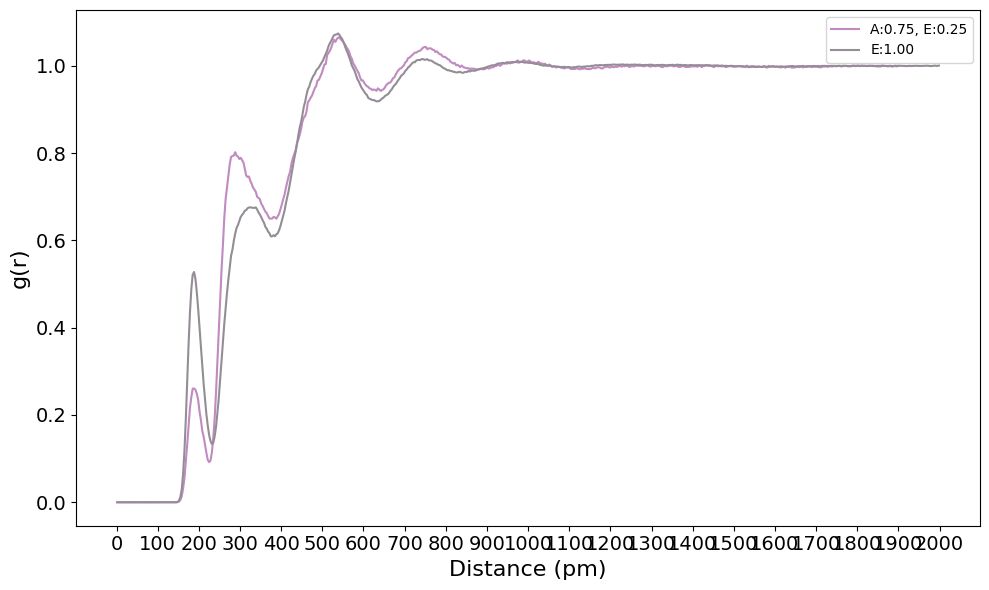

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # <--- Import this

# plt.plot(df['Distance_pm'], df['g_r'], label=path.stem)
plt.figure(figsize=(10,6))
plt.plot(df_alcohol['Distance_pm'], (df_alcohol['g_r']+df_Cl['g_r'])/(3092/3.9985042**3), label="A:0.75, E:0.25", color="#c18ac1")
plt.plot(df_pure_alcohol['Distance_pm'], df_pure_alcohol['g_r']/((351*12)/4.0060769**3), label="E:1.00", color= "#948d96")

plt.xlabel("Distance (pm)", fontsize=16)
plt.ylabel("g(r)", fontsize=16)

# --- NEW CODE HERE ---
# Get the current axis and set ticks every 100
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(100))
# ---------------------

# plt.title("All CSV g(r) Curves")
plt.legend(loc='lower right', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.legend()
plt.savefig("visc_mix.svg", dpi=300)
plt.show()